# Init:

In [2]:
%load_ext autoreload
%autoreload 2

import os
import sys
import json
import asyncio
import numpy as np
import nest_asyncio
from dotenv.main import load_dotenv

load_dotenv()
REPO_PATH = os.getenv('REPO_PATH')

sys.path.append(REPO_PATH)

nest_asyncio.apply()

def load_json(file_path):
    with open(file_path, "r", encoding="utf-8") as file:
        return json.load(file)

# 1. Load datasets:
Load all three source datasets and structure them as question-answer pairs.

In [78]:
from knowledge_maze.create_dataset.load_datasets import *

# Load all the input datasets, insert destanation path if saving is required.
tqa_dataset = load_tqa(f"{REPO_PATH}\data_files\extracted_nq.json")
nq_dataset = load_nq(f"{REPO_PATH}\data_files\extracted_squad.json")
sqd_dataset = load_sqd(f"{REPO_PATH}\data_files\extracted_triviaQA.json")

total_pairs = len(tqa_dataset) + len(nq_dataset) + len(sqd_dataset)
print(f'Loaded {total_pairs} question-answer pairs in total.')

FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\Daniel\\Desktop\\Thesis_Experiment\\QA_Datasets\\trivia_qa_train.json'

In [2]:
# Load from saved dataset:
tqa_dataset = load_json(f"{REPO_PATH}\data_files\extracted_nq.json")
nq_dataset = load_json(f"{REPO_PATH}\data_files\extracted_squad.json")
sqd_dataset = load_json(f"{REPO_PATH}\data_files\extracted_triviaQA.json")

# 2. Classify answers:
Classify answers by types - Wikipedia entities, numbers, dates and free-form.
We will merge all the candidate datasets and discard the free-form answer, also normalize the answers for easier comparison later.

In [3]:
from knowledge_maze.create_dataset.answer_classification import classify_dataset_answers

print('Processing TriviaQA:')
tqa_answer_types = await classify_dataset_answers(tqa_dataset, output_path=f"{REPO_PATH}\data_files\\tqa_answer_types.json")
print('Processing Natural Questions:')
nq_answer_types = await classify_dataset_answers(nq_dataset, output_path=f"{REPO_PATH}\data_files\\nq_answer_types.json")
print('Processing SQuAD:')
sqd_answer_types = await classify_dataset_answers(sqd_dataset, output_path=f"{REPO_PATH}\data_files\\sqd_answer_types.json")

Processing TriviaQA:


Classifying Answers: 100%|██████████████████████████████████████████████████████| 78260/78260 [03:16<00:00, 398.08it/s]


Processing Natural Questions:


Classifying Answers: 100%|████████████████████████████████████████████████████| 106926/106926 [04:22<00:00, 407.29it/s]


Processing SQuAD:


Classifying Answers: 100%|██████████████████████████████████████████████████████| 86821/86821 [03:09<00:00, 459.15it/s]


In [4]:
# Load from saved dataset:
tqa_answer_types = load_json(f"{REPO_PATH}\data_files\\tqa_answer_types.json")
nq_answer_types = load_json(f"{REPO_PATH}\data_files\\nq_answer_types.json")
sqd_answer_types = load_json(f"{REPO_PATH}\data_files\\sqd_answer_types.json")

Merged dataset contains 209055 Q-A pairs out of original 272007(77%).


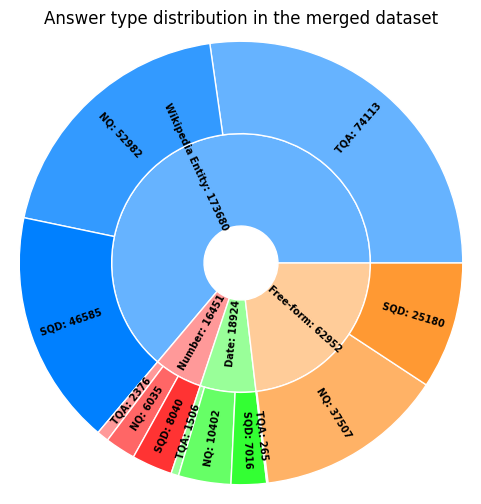

In [4]:
# Merge datasets and visualize results:
from knowledge_maze.create_dataset.answer_classification import merge_datasets

merged_dataset = merge_datasets({
                                     'TQA': tqa_answer_types,
                                     'NQ': nq_answer_types,
                                     'SQD': sqd_answer_types
                                },
                                output_path=f"{REPO_PATH}\data_files\\merged_dataset.json",
                                verbose=True)

In [10]:
# Print exapmles:
from random import choices

for sample in choices(merged_dataset, k=10):
    print(f"Question: {sample['Question']}")
    print(f"Answer: {sample['Answer']}")
    print(f"Type: {sample['Answer type']}")
    print(f"Normalized: {sample['Normalized answer']}")
    print(f"=" * 50)

Question: when did snow white and the seven dwarfs come out
Answer: 1937
Type: Date
Normalized: {'category': 'year', 'parsed_value': '1937'}
Question: What city in Rhode Island is famous for its many mansions built during the late 1800's?
Answer: Newport
Type: Wikipedia Entity
Normalized: Newport
Question: Erik the Red from Norway founded the first successful Norse settlement on Greenland, and then his son Leif continued the tradition of exploring west and landed where?
Answer: North America
Type: Wikipedia Entity
Normalized: North America
Question: What royal park shares a border with its neighbor, the park known as Kensington Gardens?
Answer: Hyde Park
Type: Wikipedia Entity
Normalized: Hyde Park
Question: How many earthquakes occurred on March 5, 2012?
Answer: twelve
Type: Number
Normalized: 12
Question: The Battle of Flodden took place in September 1513 in which English county?
Answer: Northumberland
Type: Wikipedia Entity
Normalized: Northumberland
Question: who won second place i

# 3. Group questions:

In [37]:
# Load from saved dataset:
merged_dataset = load_json(f"{REPO_PATH}\data_files\\merged_dataset.json")

In [38]:
import matplotlib.pyplot as plt
%matplotlib inline
from tqdm import tqdm
from knowledge_maze.create_dataset.cluster_questions import *

In [39]:
# Divide by answer type:
ent_data = []
num_data = []
date_data = []
for sample in merged_dataset:
    if sample['Answer type'] == 'Wikipedia Entity':
        ent_data.append(sample)
    elif sample['Answer type'] == 'Number':
        num_data.append(sample)
    else:
        date_data.append(sample)

In [396]:
# Cluster question by answer:
ent_clusters = cluster_wiki_entities(ent_data)
num_clusters = cluster_numerical_values(num_data)
date_clusters = cluster_date_values(date_data)
print(f'Total candidate clusters:')
print(f'Entities: {len(ent_clusters)} with mean cluster size of: {np.mean([len(value) for value in ent_clusters.values()]):.2f}')
print(f'Numerical: {len(num_clusters)} with mean cluster size of: {np.mean([len(value) for value in num_clusters.values()]):.2f}')
print(f'Date & Time: {len(date_clusters)} with mean cluster size of: {np.mean([len(value) for value in date_clusters.values()]):.2f}')

Total candidate clusters:
Entities: 13337 with mean cluster size of: 6.90
Numerical: 15 with mean cluster size of: 1096.73
Date & Time: 960 with mean cluster size of: 19.18


## 3.1 - Cluster and filter entity questions:

In [397]:
from knowledge_maze.create_dataset.create_reasoning_path import create_paths
entity_reasoning_chains = await create_paths(ent_clusters, output_path=f"{REPO_PATH}\data_files\\entity_reasoning_chains.json")

Generating question embeddings: 100%|██████████████████████████████████████████████████| 45/45 [01:50<00:00,  2.45s/it]
Creating similarity graphs and filtering questions: 100%|██████████████████████| 13337/13337 [00:09<00:00, 1334.68it/s]
Splitting large clusters: 100%|██████████████████████████████████████████████| 13337/13337 [00:00<00:00, 835765.14it/s]


In [214]:
# Load from folder:
entity_reasoning_chains = load_json(f"{REPO_PATH}\data_files\\entity_reasoning_chains.json")

## 3.2 - Create numerical questions reasoning paths:

In [50]:
from knowledge_maze.create_dataset.create_reasoning_path import create_paths
numerical_reasoning_chains = await create_paths(num_clusters, output_path=f"{REPO_PATH}\data_files\\numerical_reasoning_chains.json")

Generating question embeddings: 100%|████████████████████████████████████████████████████| 9/9 [00:23<00:00,  2.61s/it]
Creating similarity graphs and filtering questions: 100%|██████████████████████████████| 15/15 [00:34<00:00,  2.27s/it]
Splitting large clusters: 100%|██████████████████████████████████████████████████████| 15/15 [00:00<00:00, 2753.61it/s]


In [398]:
# Load from folder:
numerical_reasoning_chains = load_json(f"{REPO_PATH}\data_files\\numerical_reasoning_chains.json")

## 3.3 - Create date & time questions reasoning paths:

In [47]:
from knowledge_maze.create_dataset.create_reasoning_path import create_paths
date_reasoning_chains = await create_paths(date_clusters, output_path=f"{REPO_PATH}\data_files\\date_reasoning_chains.json")

Generating question embeddings: 100%|████████████████████████████████████████████████████| 9/9 [00:22<00:00,  2.53s/it]
Creating similarity graphs and filtering questions: 100%|███████████████████████████| 960/960 [00:01<00:00, 482.08it/s]
Splitting large clusters: 100%|██████████████████████████████████████████████████| 960/960 [00:00<00:00, 243104.02it/s]


In [399]:
# Load from folder:
date_reasoning_chains = load_json(f"{REPO_PATH}\data_files\\date_reasoning_chains.json")

## 3.4 - Show clusters distribution & display graph examples:

In [400]:
# Merge & save all clusters into one dataset:
reasoning_chains = list(np.concatenate([entity_reasoning_chains, numerical_reasoning_chains, date_reasoning_chains]))
output_path = f"{REPO_PATH}\data_files\\reasoning_chains.json"
with open(output_path, "w", encoding="utf-8") as out_file:
    json.dump(reasoning_chains, out_file)

In [240]:
# Load from folder:
reasoning_chains = load_json(f"{REPO_PATH}\data_files\\reasoning_chains.json")

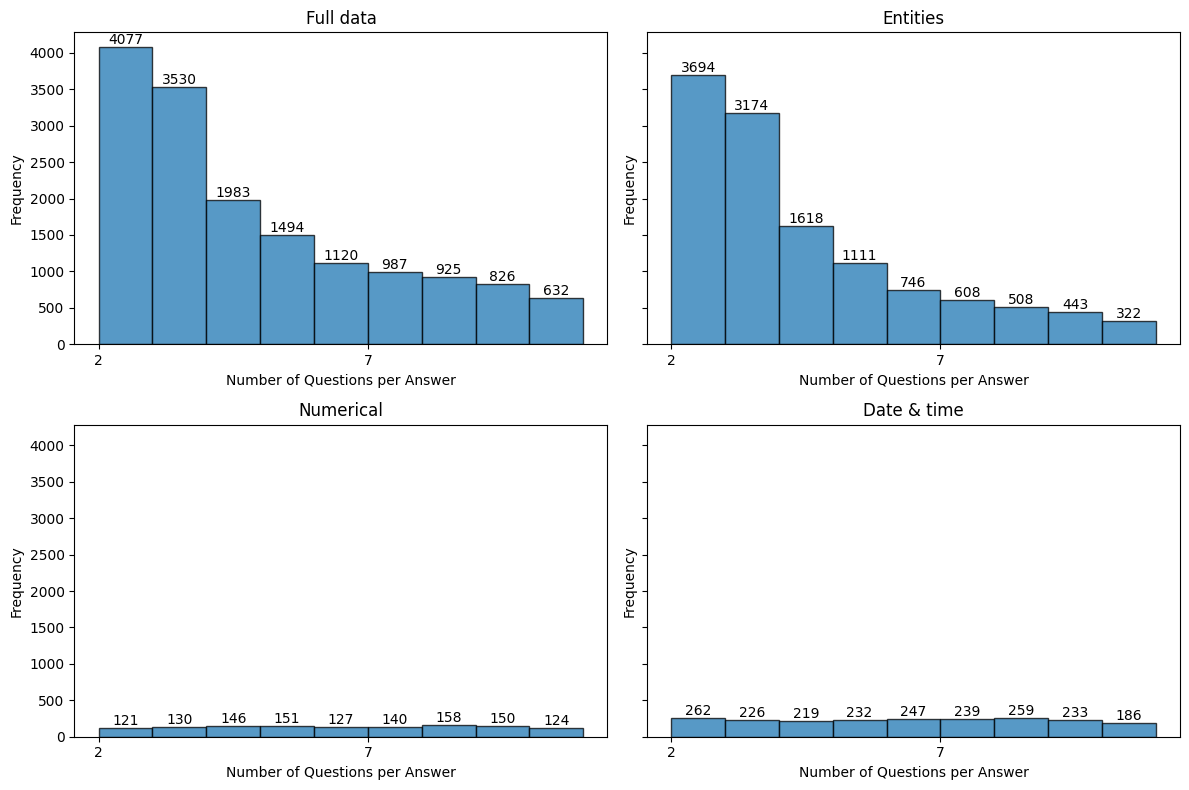

In [401]:
from knowledge_maze.create_dataset.create_reasoning_path import plot_clusters_distribution
plot_clusters_distribution({
    'Full data': reasoning_chains,
    'Entities': entity_reasoning_chains,
    'Numerical': numerical_reasoning_chains,
    'Date & time': date_reasoning_chains
})

In [57]:
from random import choice
# Plot random clusters:
print('=' * 50)
print('Entitity Cluster:')
print('=' * 50)
ent_sample = choice(entity_reasoning_chains)
print(f"Answer: {ent_sample['Answer']}")
print("List of questions:")
for question in ent_sample['Questions']:
    print(f"- {question}")
print('=' * 50)
print('Numerical Cluster:')
print('=' * 50)
ent_sample = choice(numerical_reasoning_chains)
print(f"Answer: {ent_sample['Answer']}")
print("List of questions:")
for question in ent_sample['Questions']:
    print(f"- {question}")
print('=' * 50)
print('Date & time Cluster:')
print('=' * 50)
ent_sample = choice(date_reasoning_chains)
print(f"Answer: {ent_sample['Answer']}")
print("List of questions:")
for question in ent_sample['Questions']:
    print(f"- {question}")
print('=' * 50)

Entitity Cluster:
Answer: The Grapes of Wrath
List of questions:
- For her role in which film did Jane Darwell win the 'Oscar' for Best Supporting Actress in 1940 when aged 61?
- """To the red country and part of the grey country of Oklahoma, the last rains came gently, and they did not cut the scarred earth ""is the first line of which novel?"
- What famous John Steinbeck novel featured the travels of Tom Joad?
Numerical Cluster:
Answer: (11, 50)
List of questions:
- What was the name of the room that the first exhibition of Cubists took place?
- What percentage of Norfolk Island is a permanent pasture?
- How many foreign supporters did Burke think a French royalist was worth?
- How many administrative divisions does Samoa have?
- How many Fono members are there?
- How many foreign trips did Montini make as Cardinal?
- How many of Switzerland's mountains are at least 4000 meters above sea level?
- According to the Federal Constitution, how many cantons are equal in status?
Date & time

Answer: Virat Kohli
Questions before filtering:
1. who has scored the most t20 runs for india
2. who is the indian cricket team captain 2018
3. who is the captain of indian cricket team right now
4. who won icc cricketer of the year award
5. who has been named as the cricketer of the year in the icc annual awards
6. which player highest numbers of runs in ipl history
7. who is the captain of india in cricket
8. which indian captain has won the maximum matches against sri lanka
9. who has been wisdens leading cricketer in the world for 2016
10. who scored most runs in t20 for india
11. who is the vice captain of india 2017


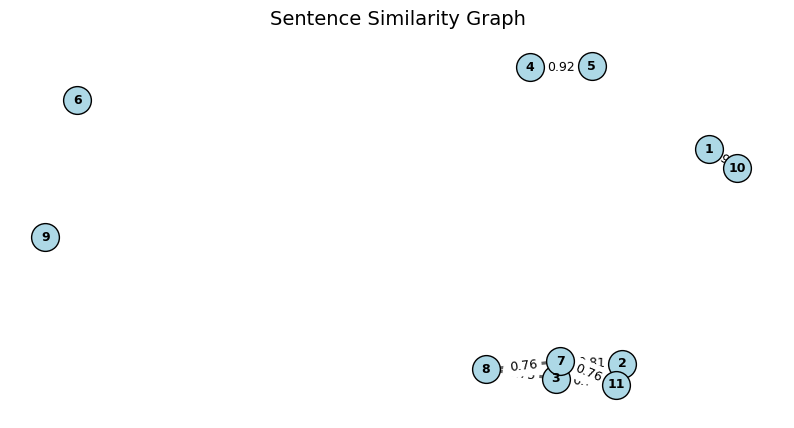

Questions after filtering:
1. who has been named as the cricketer of the year in the icc annual awards
2. which player highest numbers of runs in ipl history
3. which indian captain has won the maximum matches against sri lanka
4. who has been wisdens leading cricketer in the world for 2016
5. who scored most runs in t20 for india
6. who is the vice captain of india 2017


In [80]:
# Plot graph example - (filtering process):
from knowledge_maze.create_dataset.create_reasoning_path import display_random_sample
display_random_sample(ent_clusters, entity_questions_embeddings)

# 4. Structure Data & Generate Counter Answers:

**Dataset Structure:**
```
{
    'ID': '',
    'Question': '',
    'Answer type': '',
    'Answers': {
        'Memory answer': '',
        'Counter answer 1': '',
        'Counter answer 2': '',
        'Distractor answer': ''
    },
    'Reasoning path 1':[
        {'Previous Sub-question': '', 'Next Sub-question': '', 'Paragraph': ''},
        {'Previous Sub-question': '', 'Next Sub-question': '', 'Paragraph': ''},
        {'Previous Sub-question': '', 'Next Sub-question': '', 'Paragraph': ''},
        {'Previous Sub-question': '', 'Next Sub-question': '', 'Paragraph': ''}
    ],
    'Reasoning path 2':[
        {'Previous Sub-question': '', 'Next Sub-question': '', 'Paragraph': ''},
        {'Previous Sub-question': '', 'Next Sub-question': '', 'Paragraph': ''},
        {'Previous Sub-question': '', 'Next Sub-question': '', 'Paragraph': ''},
        {'Previous Sub-question': '', 'Next Sub-question': '', 'Paragraph': ''}
    ]
    'Distractor paragraphs': []
}
```

In [403]:
from knowledge_maze.create_dataset.create_data import process_data_to_list
structured_entities = await process_data_to_list(entity_reasoning_chains[:100], 'Wikipedia Entity')
structured_numericals = await process_data_to_list(numerical_reasoning_chains[:50], 'Numerical')
structured_dates = await process_data_to_list(date_reasoning_chains[:50], 'Date & Time')
# Merge all data:
knowledge_maze_qa = list(np.concatenate([structured_entities, structured_numericals, structured_dates]))
# Save Dataset:
output_path = f"{REPO_PATH}\data_files\\knowledge_maze_qa.json"
with open(output_path, "w", encoding="utf-8") as out_file:
    json.dump(knowledge_maze_qa, out_file)

100%|██████████████████████████████████████████████████████████████████████████████████| 50/50 [00:02<00:00, 18.36it/s]


In [ ]:
# Load from saved dataset:
knowledge_maze_qa = load_json(f"{REPO_PATH}\data_files\\knowledge_maze_qa.json")

# 5. Generate Paragraphs:

In [404]:
from knowledge_maze.create_dataset.create_data import create_paragraphs

knowledge_maze_paragraphs = await create_paragraphs(knowledge_maze_qa)

# Save Dataset:
output_path = f"{REPO_PATH}\data_files\\knowledge_maze_paragraphs.json"
with open(output_path, "w", encoding="utf-8") as out_file:
    json.dump(knowledge_maze_paragraphs, out_file)

Usage cost: 0.0354$ (Estimated: 0.04$): 100%|████████████████████████████████████████| 370/370 [00:17<00:00, 21.60it/s]


In [ ]:
# Load from saved dataset:
knowledge_maze_paragraphs = load_json(f"{REPO_PATH}\data_files\\knowledge_maze_paragraphs.json")

In [419]:
def count_matching_questions(words_or_phrases, questions):
    """
    Counts how many questions contain at least one word or phrase from the given list, case-insensitively.

    Args:
        words_or_phrases (list[str]): List of words or phrases to search for.
        questions (list[str]): List of questions to check.

    Returns:
        int: Number of questions containing at least one word or phrase, regardless of case.
    """
    when_count = 0
    count = 0
    for question in questions:
        # Convert question to lowercase and check against lowercased words/phrases
        if any(phrase.lower() in question.lower() for phrase in words_or_phrases):
            count += 1
        else:
            if 'When' in question:
                when_count+= 1
                print(question)
    print(when_count)
    return count

In [420]:
total = len(num_ques)
phrases = ["How much", "How many", "The number", "Total", "How old", "age", "times", "number of", "Which number"]
print(f"{count_matching_questions(phrases, num_ques)} / {total}")

When was St. Patrick born? 347, 741 or 1374?
When Corporation Tax was first introduced in 1965, what was the basic rate? Was it 20%, 30% or 40% ?
When measured in metres per second, in a vacuum, what's the speed of light to the nearest million ?
When was the bridge celebrated in the French nursery song new?
When did St Francis of Assisi found the Order of the Friars Minor?
When Malaysian Airlines Flight MH17 was brought down by hostile fire over East Ukraine on 17 July 2014 what was the death toll of passengers and crew?
When Kobe Bryant of the Lakers played the farewell game of his 20 year NBA career in 2016 what was his score as part of his side's 101-96 win?
When Apple introduced the I-phone into the UK in 2007 which was the only mobile phone company licensed to use it?
When did Ulrich do his sonnet on Chopin?
When was the Mongol-Tibetan alliance started?
When did Kublai Khan conquer the song dynasty?  
When did the yuan dynasty start and end?
When did Deshin Shekpa travels start?
W